# Derivatives in 2D

We will revise how to compute derivatives in 2D. In particular, we will compute the:

- Gradient of scalar fields


- Curl of vector fields


- Divergence of vector fields


To illustrate the process, we will use data from the ($50\times 50$ pixels) turbulence simulation that we studied earlier, plus one more simulatin ran on a finer grid (i.e. at higher numerical resolution, $200\times 200$ pixels)).

### Data:

We will use the same database of a turbulence-in-a-box model:

- TURB_DRIVE_SUP_hr

Repository: https://www.dropbox.com/scl/fo/aip4lo4983phsyd5tcn77/ALvNSCjfQpzlbjrKmhP5Ex8?rlkey=m4ragdal7lagwczhtkvyqj0ty&dl=0

In [1]:
# Import libraries

import pyvista as pv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Get CGS normalisation units from units.out:

In [2]:
units_data = pd.read_csv("/Users/wbandabarragan/Library/CloudStorage/Dropbox/Nyuszik/python_course/computational-physics-1-main/unit-3/TURB_DRIVE_SUP_hr/units.out")

#print(units_data)

In [3]:
# Normalisation values
rho_00   = np.array(units_data.loc[units_data["variable"] == "rho_0"]["normalisation"])
vel_00   = np.array(units_data.loc[units_data["variable"] == "v_0"]["normalisation"])
len_00   = np.array(units_data.loc[units_data["variable"] == "L_0"]["normalisation"])
c_iso   = np.array(units_data.loc[units_data["variable"] == "c_iso"]["normalisation"])

# Derived normalisation values
tim_00 = (len_00/vel_00)
bfi_00 = (np.sqrt(4*np.pi*rho_00*vel_00**2))

## Read meshes:

In [4]:
mesh_hr = pv.read("/Users/wbandabarragan/Library/CloudStorage/Dropbox/Shared_folder/Data_Session3/simulation_data/TURB_DRIVE_SUP_HR/data.0010.vtk")
#print(mesh_hr)

## Read arrays:

In [5]:
# Getting the data arrays
rho_hr = pv.get_array(mesh_hr, "rho", preference = 'cell') #density in code units
vx1_hr = pv.get_array(mesh_hr, "vx1", preference = 'cell') #vx in code units
vx2_hr = pv.get_array(mesh_hr, "vx2", preference = 'cell') #vy in code units

Bx1_hr = pv.get_array(mesh_hr, "Bx1", preference = 'cell') #Bx in code units
Bx2_hr = pv.get_array(mesh_hr, "Bx2", preference = 'cell') #By in code units    

## 2D conversion:

In [6]:
# Convert the arrays to 2D
rho_2D_hr = rho_hr.reshape(mesh_hr.dimensions[0] - 1, mesh_hr.dimensions[1] - 1)
vx1_2D_hr = vx1_hr.reshape(mesh_hr.dimensions[0] - 1, mesh_hr.dimensions[1] - 1)
vx2_2D_hr = vx2_hr.reshape(mesh_hr.dimensions[0] - 1, mesh_hr.dimensions[1] - 1)
Bx1_2D_hr = Bx1_hr.reshape(mesh_hr.dimensions[0] - 1, mesh_hr.dimensions[1] - 1)
Bx2_2D_hr = Bx2_hr.reshape(mesh_hr.dimensions[0] - 1, mesh_hr.dimensions[1] - 1)

# Convert arrays to CGS units
rho_cgs2D_hr = rho_2D_hr*rho_00
vx1_cgs2D_hr = vx1_2D_hr*vel_00
vx2_cgs2D_hr = vx2_2D_hr*vel_00
Bx1_cgs2D_hr = Bx1_2D_hr*bfi_00
Bx2_cgs2D_hr = Bx2_2D_hr*bfi_00

## Create grids for plotting:

In [7]:
x_hr = np.linspace(mesh_hr.bounds[0]*len_00, mesh_hr.bounds[1]*len_00, mesh_hr.dimensions[0] - 1)
y_hr = np.linspace(mesh_hr.bounds[2]*len_00, mesh_hr.bounds[3]*len_00, mesh_hr.dimensions[1] - 1)

X_hr, Y_hr = np.meshgrid(x_hr, y_hr)

#print(X_hr.shape)

## Plotting:

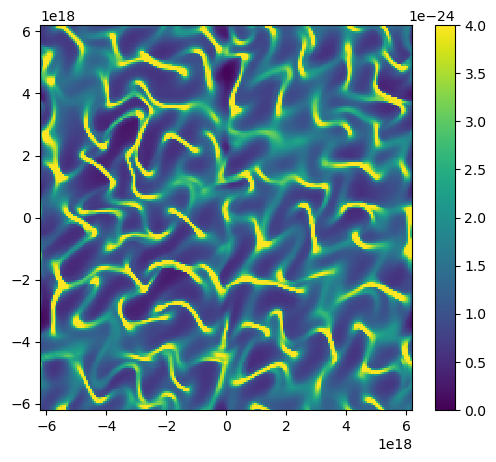

In [8]:
plt.figure(figsize = (6,5))

Z1 = plt.pcolor(X_hr, Y_hr, rho_cgs2D_hr, cmap = 'viridis', shading = 'auto',  vmin = 0, vmax= 4.e-24)

CB1 = plt.colorbar(Z1)

plt.show()

# A. Gradient of scalar functions:

## Example:

Calculate the gradient of the density field: $\vec{\nabla} \rho$


### 1. Using `numpy.gradient()`:

https://numpy.org/doc/stable/reference/generated/numpy.gradient.html

### First, we need to define the x-spacing:

In [9]:
dx_hr = np.array(x_hr[1] - x_hr[0], dtype=float)

print(dx_hr[0])

6.203015075376845e+16


### Then, we calculate the gradient:

In [10]:
gradient_rho_hr = np.gradient(rho_cgs2D_hr, dx_hr[0])

### which returns a tuple containing the arrays with the components of the gradient:

$\frac{\partial \rho}{\partial x}$ along $x$.


$\frac{\partial \rho}{\partial y}$ along $y$.

### Get gradient components and its modulus:

In [11]:
xgradient_rho_hr = gradient_rho_hr[0]
ygradient_rho_hr = gradient_rho_hr[1]

modulus_gradient_rho_hr = np.sqrt(xgradient_rho_hr**2 + ygradient_rho_hr**2)

### Then, we check that the units are consistent with the expected dimensions:

$\frac{\partial \rho}{\partial x}$ has units of $[M\,L^{-3}]/[L] = [M\,L^{-4}]$


In [12]:
print(np.max(rho_cgs2D_hr))
print(x_hr[1] - x_hr[0])

print(np.max(rho_cgs2D_hr)/(x_hr[1] - x_hr[0]))

2.2294334011077883e-23
[6.20301508e+16]
[3.5941125e-40]


In [13]:
print(np.max(modulus_gradient_rho_hr))

1.7556361806717732e-40


### Finally, we make plots of the gradient vector:

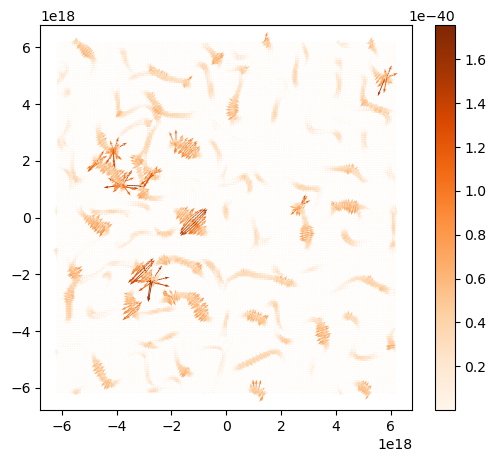

In [14]:
plt.figure(figsize = (6,5))

Z2 = plt.quiver(X_hr, Y_hr, ygradient_rho_hr, xgradient_rho_hr, modulus_gradient_rho_hr, cmap = 'Oranges')#, clim = (0, 1.e-40))

CB2 = plt.colorbar(Z2)

plt.show()

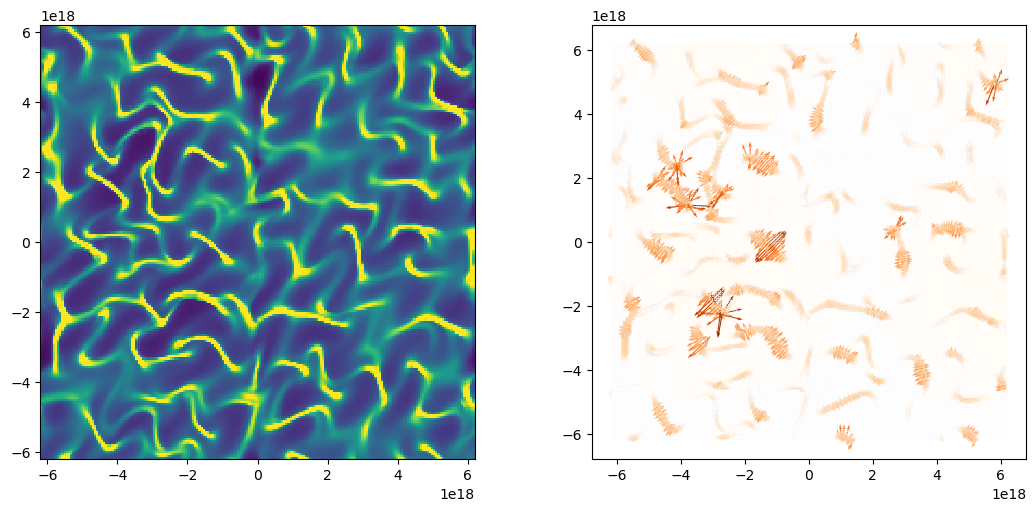

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)

axs[0].pcolor(X_hr, Y_hr, rho_cgs2D_hr, cmap='viridis',
              shading='auto', vmin=0, vmax=4.e-24)
axs[1].quiver(X_hr, Y_hr, ygradient_rho_hr, xgradient_rho_hr,
              modulus_gradient_rho_hr, cmap='Oranges')

for ax in axs:
    ax.set_aspect('equal')      # one data unit in x = one in y

#### Plot of the magnitude of the gradients:

Notice how we can see the edges of the filaments.

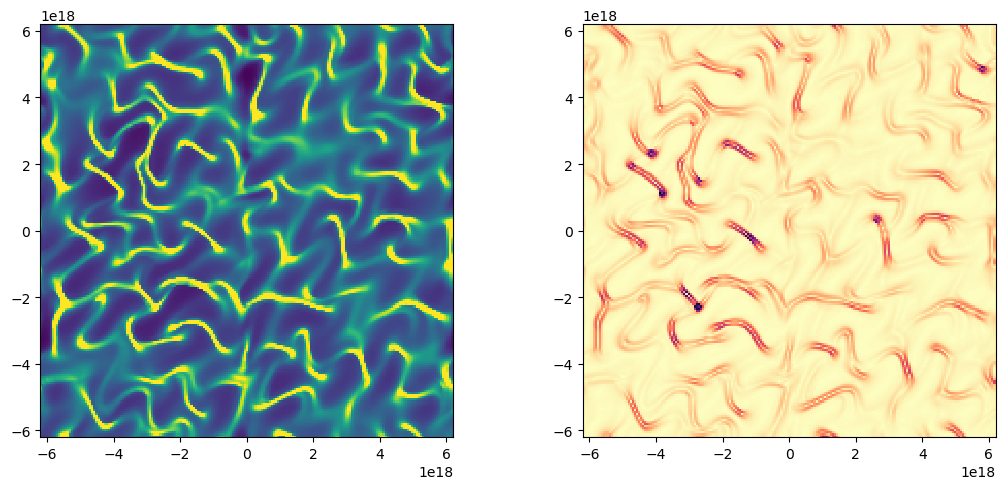

In [16]:
fig, axs = plt.subplots(1,2, figsize=(11, 5))

axs[0].pcolor(X_hr, Y_hr, rho_cgs2D_hr, cmap = 'viridis',\
              shading = 'auto', vmin = 0, vmax = 4.e-24)
axs[1].pcolor(X_hr, Y_hr, modulus_gradient_rho_hr, cmap = 'magma_r', shading = 'auto')#, clim = (0, 1.e-40), shading = 'auto')

fig.tight_layout()
for ax in axs:
    ax.set_aspect('equal')      # one data unit in x = one in y

## Edge detection:

Notice that the gradients are capturing the edges of the filaments. 

We have constructed an edge detector.

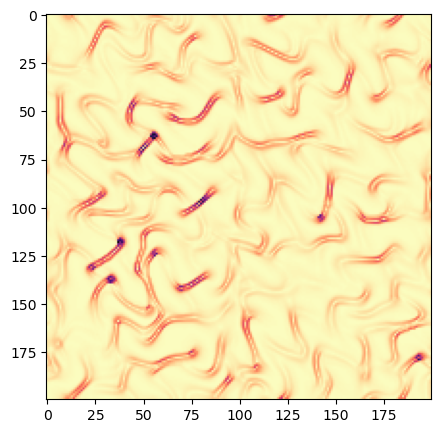

In [17]:
plt.figure(figsize=(6,5))

plt.imshow(modulus_gradient_rho_hr, cmap = 'magma_r')
plt.show()

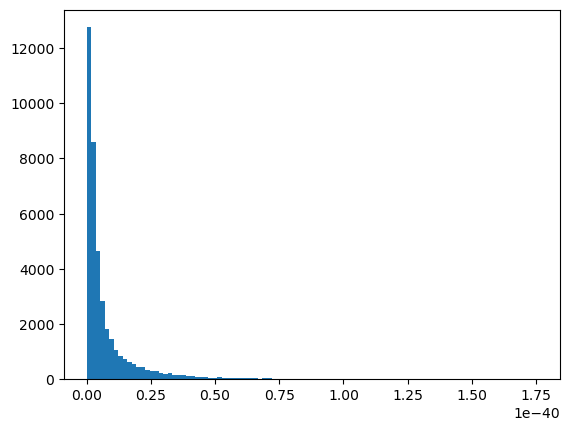

In [18]:
# Make a histogram
modulus_1d = modulus_gradient_rho_hr.flatten()

plt.figure()

plt.hist(modulus_1d, bins = 100)
plt.show()

### Thresholding algorithm:

In [19]:
print(np.min(modulus_1d), np.max(modulus_1d))

5.510846709523194e-45 1.7556361806717732e-40


In [20]:
# Isoolate the large gradients

modulus_1d_clean = np.where(modulus_1d > np.min(modulus_1d)*2.e3,1.,0.)

modulus_2d_clean = modulus_1d_clean.reshape(modulus_gradient_rho_hr.shape)

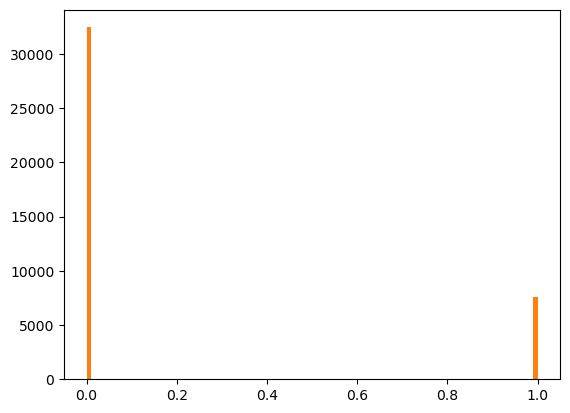

In [21]:
# Make a histogram
modulus_1d = modulus_gradient_rho_hr.flatten()

plt.figure()

plt.hist(modulus_1d, bins = 100)

plt.hist(modulus_1d_clean, bins = 100)
plt.show()

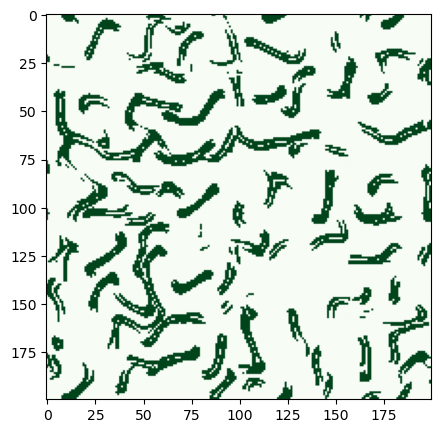

In [22]:
plt.figure(figsize=(6,5))

plt.imshow(modulus_2d_clean, cmap = 'Greens')
plt.show()

## B. Curl of vector fields:


$$\vec{\omega}= \vec{\nabla} \times \vec{v}$$

In [23]:
modulus_speed_hr = np.sqrt(vx1_cgs2D_hr**2 + vx2_cgs2D_hr**2)

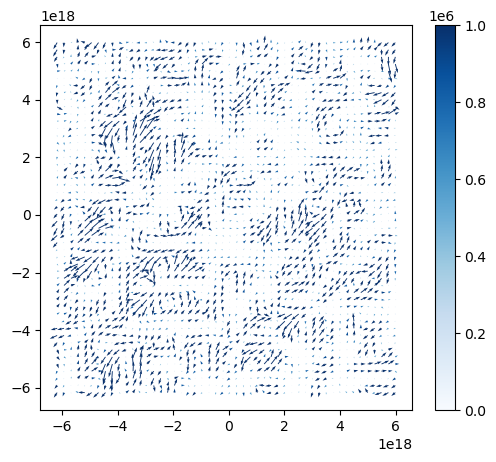

In [24]:
# keep every 4th point

s = 4                                   

plt.figure(figsize = (6,5))

Z = plt.quiver(X_hr[::s, ::s], Y_hr[::s, ::s], vx1_cgs2D_hr[::s, ::s], vx2_cgs2D_hr[::s, ::s], modulus_speed_hr[::s, ::s], cmap = 'Blues', clim = (0, 1.e6))#, angles='xy', scale_units='xy', scale=1)

CB = plt.colorbar(Z)

plt.show()

# Curl:

In [25]:
def get_curl(comp1, comp2, dx):
    """
    Get curl of vector field.
    """
    curl1 = np.gradient(comp1, dx, axis = 0)
    curl2 = np.gradient(comp2, dx, axis = 1)
    curlt = curl2 - curl1
    
    return curlt

In [26]:
xx = np.linspace(mesh_hr.bounds[0], mesh_hr.bounds[1], mesh_hr.dimensions[0] - 1)
yy = np.linspace(mesh_hr.bounds[2], mesh_hr.bounds[3], mesh_hr.dimensions[1] - 1)

dxx = xx[1] - xx[0]


print(dxx)

0.0201005025125629


In [27]:
curl_vel_hr = get_curl(vx1_cgs2D_hr, vx2_cgs2D_hr, dxx)

In [28]:
print(np.max(curl_vel_hr))
print(np.min(curl_vel_hr))

72725524.55961673
-74302472.80001608


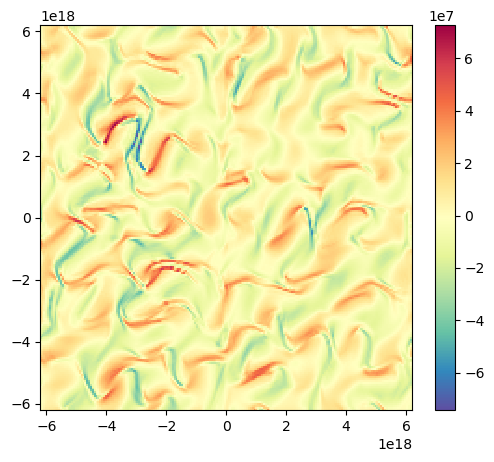

In [29]:
plt.figure(figsize = (6,5))

Z2 = plt.pcolor(X_hr, Y_hr, curl_vel_hr, cmap = 'Spectral_r', shading = 'auto')#, vmin = -8e7, vmax = 8.e7)

CB2 = plt.colorbar(Z2)

plt.show()

## C. Divergence of vector fields:


$$\vec{\nabla}\cdot \vec{B}= 0$$

In [30]:
def get_divergence(comp1, comp2, dx):
    
    """
    Function to get div of any vector.
    """
    
    div1 = np.gradient(comp1, dx, axis = 1)
    div2 = np.gradient(comp2, dx, axis = 0)
    
    divt = div1 + div2
    
    return divt

### High-resolution $B$

In [31]:
# Magnitude of the magnetic field

modulus_bfield_hr = np.sqrt(Bx1_cgs2D_hr**2 + Bx2_cgs2D_hr**2)

In [32]:
print(Bx1_cgs2D_hr.shape)

(200, 200)


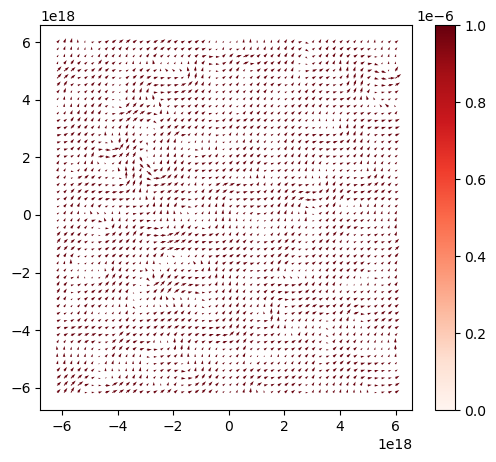

In [33]:
s = 4

plt.figure(figsize = (6,5))

Z = plt.quiver(X_hr[::s, ::s], Y_hr[::s, ::s], Bx1_cgs2D_hr[::s, ::s], Bx2_cgs2D_hr[::s, ::s], modulus_bfield_hr[::s, ::s], cmap = 'Reds', clim = (0, 1.e-6))#, angles='xy', scale_units='xy', scale=1)

CB = plt.colorbar(Z)

plt.show()

In [34]:
div_bfield_hr = get_divergence(Bx1_cgs2D_hr, Bx2_cgs2D_hr, dxx)

#print(np.max(div_bfield_hr))
#print(np.min(div_bfield_hr))

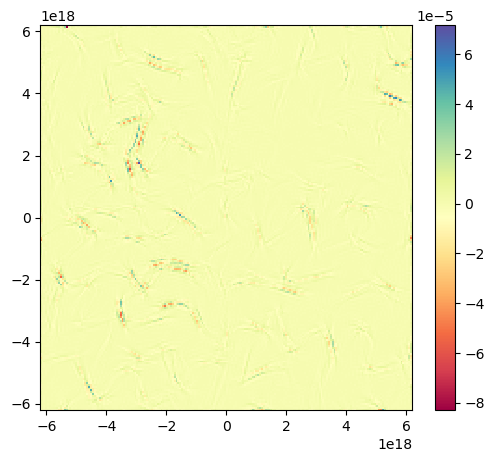

In [35]:
plt.figure(figsize = (6,5))

Z2 = plt.pcolor(X_hr, Y_hr, div_bfield_hr, cmap = 'Spectral', shading = 'auto')#, vmin = -8e-12, vmax = 8.e-12)

CB2 = plt.colorbar(Z2)

plt.show()

### 2nd option:

In [36]:
# Divergence function
def divergence(f,sp):
    num_dims = len(f)
    print(num_dims)
    #print(sp[0])
    return np.ufunc.reduce(np.add, [np.gradient(f[i], sp, axis=i) for i in range(num_dims)])


In [37]:
F = np.array([Bx2_cgs2D_hr, Bx1_cgs2D_hr])
sp_x = np.diff(xx)[0]

print(sp_x)

#print(F[0])

0.0201005025125629


In [38]:
div_bfield_hr2 = divergence(F, sp_x)

2


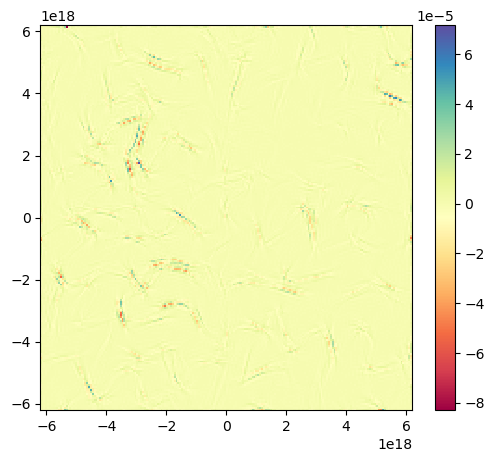

In [39]:
plt.figure(figsize = (6,5))

Z2 = plt.pcolor(X_hr, Y_hr, div_bfield_hr2, cmap = 'Spectral', shading = 'auto')#, vmin = -8e-12, vmax = 8.e-12)

CB2 = plt.colorbar(Z2)

plt.show()